Importation des données

In [34]:
import pandas as pd

df = pd.read_csv("Envoy_Air.csv")

print(df.shape)


(1072778, 61)


Dimensions et apreçu

In [35]:
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

display(df.head())

df.info()

Nombre de lignes : 1072778
Nombre de colonnes : 61


,FlightDate,Airline,Origin,Dest,Cancelled,Diverted,CRSDepTime,DepTime,DepDelayMinutes,DepDelay,...,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrDelay,ArrDel15,ArrivalDelayGroups,ArrTimeBlk,DistanceGroup,DivAirportLandings
0,2018-10-26,Envoy Air,IAH,ORD,False,False,1137,1132.0,0.0,-5.0,...,1146.0,1353.0,13.0,1420,-14.0,0.0,-1.0,1400-1459,4,0.0
1,2018-10-27,Envoy Air,IAH,ORD,False,False,1137,1137.0,0.0,0.0,...,1156.0,1412.0,12.0,1420,4.0,0.0,0.0,1400-1459,4,0.0
2,2018-10-28,Envoy Air,IAH,ORD,False,False,1137,1140.0,3.0,3.0,...,1153.0,1410.0,7.0,1420,-3.0,0.0,-1.0,1400-1459,4,0.0
3,2018-10-29,Envoy Air,IAH,ORD,False,False,1137,1134.0,0.0,-3.0,...,1145.0,1357.0,8.0,1420,-15.0,0.0,-1.0,1400-1459,4,0.0
4,2018-10-30,Envoy Air,IAH,ORD,False,False,1137,1129.0,0.0,-8.0,...,1137.0,1340.0,9.0,1420,-31.0,0.0,-2.0,1400-1459,4,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1072778 entries, 0 to 1072777
Data columns (total 61 columns):
 #   Column                                   Non-Null Count    Dtype  
---  ------                                   --------------    -----  
 0   FlightDate                               1072778 non-null  object 
 1   Airline                                  1072778 non-null  object 
 2   Origin                                   1072778 non-null  object 
 3   Dest                                     1072778 non-null  object 
 4   Cancelled                                1072778 non-null  bool   
 5   Diverted                                 1072778 non-null  bool   
 6   CRSDepTime                               1072778 non-null  int64  
 7   DepTime                                  1038038 non-null  float64
 8   DepDelayMinutes                          1038032 non-null  float64
 9   DepDelay                                 1038032 non-null  float64
 10  ArrTime           

Types de variables

In [36]:
display(
    df.dtypes.value_counts()
)

display(
    df.dtypes.to_frame(name="Type")
)

int64      22
float64    19
object     18
bool        2
Name: count, dtype: int64

,Type
FlightDate,object
Airline,object
Origin,object
Dest,object
Cancelled,bool
...,...
ArrDel15,float64
ArrivalDelayGroups,float64
ArrTimeBlk,object
DistanceGroup,int64


Valeurs manquantes

In [37]:
missing_df = pd.DataFrame({
    "Valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": (df.isnull().mean() * 100).round(2)
})

missing_df = missing_df[
    missing_df["Valeurs manquantes"] > 0
]

display(
    missing_df.sort_values(
        by="Pourcentage (%)",
        ascending=False
    )
)

,Valeurs manquantes,Pourcentage (%)
ArrivalDelayGroups,38799,3.62
ArrDel15,38799,3.62
ArrDelayMinutes,38799,3.62
AirTime,38799,3.62
ActualElapsedTime,38799,3.62
ArrDelay,38799,3.62
ArrTime,36389,3.39
TaxiIn,36389,3.39
WheelsOn,36389,3.39
WheelsOff,35857,3.34


Doublons

In [38]:
print("Lignes dupliquées :", df.duplicated().sum())

print(
    "Pourcentage de doublons :",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

Lignes dupliquées : 0
Pourcentage de doublons : 0.0 %


Distribution de la variable cible

In [39]:
# Nombre de vols par classe
display(df["ArrDel15"].value_counts(dropna=False))

# Pourcentage par classe
display(
    (df["ArrDel15"].value_counts(
        normalize=True,
        dropna=False
    ) * 100).round(2)
)

ArrDel15
0.0    854156
1.0    179823
NaN     38799
Name: count, dtype: int64

ArrDel15
0.0    79.62
1.0    16.76
NaN     3.62
Name: proportion, dtype: float64

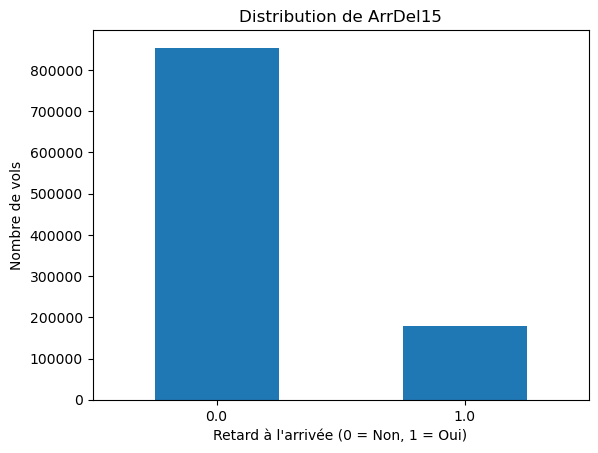

In [40]:
import matplotlib.pyplot as plt

df["ArrDel15"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution de ArrDel15")
plt.xlabel("Retard à l'arrivée (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de vols")
plt.xticks(rotation=0)
plt.show()

Suppression des variables pour évité le DataLeak

In [41]:
# ==========================================
# 1. SUPPRESSION DES VARIABLES CAUSANT DU DATA LEAKAGE
# ==========================================

# Variables à supprimer :
# ArrDelay : retard réel à l'arrivée en minutes.
# ArrDelayMinutes : nombre de minutes de retard à l'arrivée.
# ArrivalDelayGroups : catégorie calculée à partir du retard à l'arrivée.
# ArrTime : heure réelle d'arrivée.
# WheelsOn : heure réelle d'atterrissage.
# WheelsOff : heure réelle de décollage.
# DepTime : heure réelle de départ.
# DepDelay : différence entre l'heure prévue et réelle de départ.
# DepDelayMinutes : minutes de retard au départ.
# DepDel15 : indicateur de retard réel au départ.
# DepartureDelayGroups : catégorie calculée à partir du retard au départ.
# TaxiOut : temps réel entre la porte et le décollage.
# TaxiIn : temps réel entre l'atterrissage et la porte.
# ActualElapsedTime : durée réelle du vol.
# AirTime : temps réel passé en vol.
# CarrierDelay : minutes de retard attribuées à la compagnie.
# WeatherDelay : minutes de retard attribuées à la météo.
# NASDelay : minutes de retard attribuées au système aérien.
# SecurityDelay : minutes de retard attribuées à la sécurité.
# LateAircraftDelay : minutes de retard causées par l'avion précédent.

leakage_cols = [
    "ArrDelay",
    "ArrDelayMinutes",
    "ArrivalDelayGroups",
    "ArrTime",
    "WheelsOn",
    "WheelsOff",
    "DepTime",
    "DepDelay",
    "DepDelayMinutes",
    "DepDel15",
    "DepartureDelayGroups",
    "TaxiOut",
    "TaxiIn",
    "ActualElapsedTime",
    "AirTime",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

# Supprimer uniquement les colonnes présentes dans le dataset
cols_to_drop = [col for col in leakage_cols if col in df.columns]

df = df.drop(columns=cols_to_drop)

# Afficher les résultats
print("Nombre de colonnes supprimées :", len(cols_to_drop))
print("Colonnes supprimées :", cols_to_drop)

print("\nDimensions restantes :", df.shape)

Nombre de colonnes supprimées : 15
Colonnes supprimées : ['ArrDelay', 'ArrDelayMinutes', 'ArrivalDelayGroups', 'ArrTime', 'WheelsOn', 'WheelsOff', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepDel15', 'DepartureDelayGroups', 'TaxiOut', 'TaxiIn', 'ActualElapsedTime', 'AirTime']

Dimensions restantes : (1072778, 46)


Distribution des vols annulés

In [42]:
# Nombre de vols annulés et non annulés
display(df["Cancelled"].value_counts(dropna=False))

# Pourcentage
display(
    (df["Cancelled"].value_counts(normalize=True, dropna=False) * 100).round(2)
)

Cancelled
False    1036655
True       36123
Name: count, dtype: int64

Cancelled
False    96.63
True      3.37
Name: proportion, dtype: float64

Distribution des vols déroutés

In [43]:
# Nombre de vols déroutés et non déroutés
display(df["Diverted"].value_counts(dropna=False))

# Pourcentage
display(
    (df["Diverted"].value_counts(normalize=True, dropna=False) * 100).round(2)
)

Diverted
False    1070102
True        2676
Name: count, dtype: int64

Diverted
False    99.75
True      0.25
Name: proportion, dtype: float64

Distribution de la variable cible

In [44]:
# Nombre de vols par classe
display(df["ArrDel15"].value_counts(dropna=False))

# Pourcentage par classe
display(
    (df["ArrDel15"].value_counts(normalize=True, dropna=False) * 100).round(2)
)

ArrDel15
0.0    854156
1.0    179823
NaN     38799
Name: count, dtype: int64

ArrDel15
0.0    79.62
1.0    16.76
NaN     3.62
Name: proportion, dtype: float64

Croiser les informations

In [45]:
# Examiner les vols annulés selon la variable cible
display(pd.crosstab(df["Cancelled"], df["ArrDel15"], dropna=False))

# Examiner les vols déroutés selon la variable cible
display(pd.crosstab(df["Diverted"], df["ArrDel15"], dropna=False))

ArrDel15,0.0,1.0,NaN
Cancelled,,,
False,854156,179823,2676
True,0,0,36123


ArrDel15,0.0,1.0,NaN
Diverted,,,
False,854156,179823,36123
True,0,0,2676


Nettoyer les vols annulés et déroutés

In [46]:
# ==========================================
# 5. SUPPRESSION DES VOLS ANNULÉS ET DÉROUTÉS
# ==========================================

# Supprimer les vols annulés :
# Un vol annulé ne peut pas avoir de retard à l'arrivée.
# Ces vols ne sont donc pas pertinents pour notre classification.

df = df[df["Cancelled"] == False]

# Supprimer les vols déroutés :
# Un vol dérouté n'atteint pas nécessairement sa destination prévue.
# Il ne représente pas un cas classique de retard à l'arrivée.

df = df[df["Diverted"] == False]

# Supprimer les colonnes Cancelled et Diverted :
# Leur statut réel n'est pas connu avant le départ.
# Elles ne peuvent donc pas être utilisées comme variables prédictives.

df = df.drop(columns=["Cancelled", "Diverted"])

# Afficher les dimensions après nettoyage
print("Dimensions après nettoyage :", df.shape)

# Vérifier les valeurs manquantes de la cible
print("\nValeurs manquantes dans ArrDel15 :")
print(df["ArrDel15"].isnull().sum())

Dimensions après nettoyage : (1033979, 44)

Valeurs manquantes dans ArrDel15 :
0


Vérifier la distribution de la cible après nettoyage

In [47]:
# ==========================================
# 6. DISTRIBUTION DE LA VARIABLE CIBLE
# ==========================================

# Nombre de vols par classe
display(df["ArrDel15"].value_counts())

# Pourcentage par classe
display(
    (df["ArrDel15"].value_counts(normalize=True) * 100).round(2)
)

ArrDel15
0.0    854156
1.0    179823
Name: count, dtype: int64

ArrDel15
0.0    82.61
1.0    17.39
Name: proportion, dtype: float64

Examiner les valeurs manquantes restantes

In [48]:
# Calculer le nombre et le pourcentage de valeurs manquantes
missing_df = pd.DataFrame({
    "Valeurs manquantes": df.isnull().sum(),
    "Pourcentage (%)": (df.isnull().mean() * 100).round(2)
})

# Garder uniquement les colonnes ayant des valeurs manquantes
missing_df = missing_df[
    missing_df["Valeurs manquantes"] > 0
]

# Trier par ordre décroissant
missing_df = missing_df.sort_values(
    by="Pourcentage (%)",
    ascending=False
)

display(missing_df)

,Valeurs manquantes,Pourcentage (%)


DÉTECTION DES DOUBLONS

In [49]:

# Nombre de lignes dupliquées
print("Nombre de doublons :", df.duplicated().sum())

# Pourcentage de doublons
print(
    "Pourcentage de doublons :",
    round(df.duplicated().mean() * 100, 2),
    "%"
)

Nombre de doublons : 0
Pourcentage de doublons : 0.0 %


DÉTECTION DES COLONNES DUPLIQUÉES

In [50]:
duplicated_cols = []

cols = df.columns.tolist()

for i in range(len(cols)):
    for j in range(i + 1, len(cols)):

        # Comparer deux colonnes
        if df[cols[i]].equals(df[cols[j]]):
            duplicated_cols.append((cols[i], cols[j]))

print("Paires de colonnes identiques :", duplicated_cols)
print("Nombre de paires :", len(duplicated_cols))

Paires de colonnes identiques : [('Marketing_Airline_Network', 'IATA_Code_Marketing_Airline'), ('Flight_Number_Marketing_Airline', 'Flight_Number_Operating_Airline'), ('Operating_Airline', 'IATA_Code_Operating_Airline')]
Nombre de paires : 3


Supression des colonnes dupliquées

In [51]:
duplicated_cols_to_drop = [
    "IATA_Code_Marketing_Airline",
    "Flight_Number_Operating_Airline",
    "IATA_Code_Operating_Airline"
]

# Suppression des colonnes redondantes
df = df.drop(columns=duplicated_cols_to_drop)

# Vérification
print("Colonnes supprimées :", duplicated_cols_to_drop)
print("Nombre de colonnes restantes :", df.shape[1])
print("Dimensions du dataset :", df.shape)

Colonnes supprimées : ['IATA_Code_Marketing_Airline', 'Flight_Number_Operating_Airline', 'IATA_Code_Operating_Airline']
Nombre de colonnes restantes : 41
Dimensions du dataset : (1033979, 41)


Analyse de la suppression des colonnes dupliquées

In [52]:

# Marketing_Airline_Network conservée :
# Plus adaptée pour identifier une compagnie sur plusieurs années.
# IATA_Code_Marketing_Airline supprimée : contient les mêmes valeurs.

# Flight_Number_Marketing_Airline conservée :
# On garde le numéro de vol marketing.
# Flight_Number_Operating_Airline supprimée : contient les mêmes valeurs.

# Operating_Airline conservée :
# Identifie le transporteur avec son code unique.
# IATA_Code_Operating_Airline supprimée : contient les mêmes valeurs.

Examination des variables catégorielles

In [53]:

# Identifier les variables catégorielles
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

print("Nombre de variables catégorielles :", len(categorical_cols))

# Examiner chaque variable
for col in categorical_cols:

    print(f"\n--- {col} ---")

    print("Nombre de catégories :", df[col].nunique())

    display(df[col].value_counts().head(15))

Nombre de variables catégorielles : 16

--- FlightDate ---
Nombre de catégories : 1461


FlightDate
2019-08-09    1011
2019-07-26    1010
2019-07-28    1007
2019-08-05    1007
2019-08-02    1005
2019-07-12    1005
2019-07-24    1005
2019-08-11    1002
2019-07-19     999
2019-08-16     998
2019-08-29     997
2019-08-04     995
2019-07-25     993
2019-08-01     993
2019-07-09     990
Name: count, dtype: int64


--- Airline ---
Nombre de catégories : 1


Airline
Envoy Air    1033979
Name: count, dtype: int64


--- Origin ---
Nombre de catégories : 190


Origin
DFW    231420
ORD    187610
MIA     42385
LGA     19348
SGF     16273
XNA     15198
CVG     15048
CMH     13819
CLT     13102
LIT     12929
GSO      9320
CLE      7694
ABI      7596
JFK      7589
GRK      7526
Name: count, dtype: int64

... (22 outputs left out)


--- DepTimeBlk ---
Nombre de catégories : 19


DepTimeBlk
1200-1259    86701
1000-1059    86212
0800-0859    80026
0600-0659    75848
1600-1659    73840
1400-1459    71190
1800-1859    71168
1500-1559    63280
0700-0759    59092
1300-1359    56692
1700-1759    54340
1100-1159    53850
2000-2059    52505
0900-0959    46403
1900-1959    39685
Name: count, dtype: int64


--- ArrTimeBlk ---
Nombre de catégories : 19


ArrTimeBlk
1100-1159    85832
1700-1759    85174
1500-1559    79104
0900-0959    75474
1900-1959    75081
1400-1459    66789
1200-1259    64441
0700-0759    62475
1300-1359    61144
1600-1659    56266
1000-1059    55407
2100-2159    55085
1800-1859    52216
2200-2259    39973
2000-2059    37044
Name: count, dtype: int64

Supression des variables constantes

In [54]:

# Airline : une seule compagnie (Envoy Air).
# Marketing_Airline_Network : une seule valeur (AA).
# Operated_or_Branded_Code_Share_Partners :
# une seule valeur (AA_CODESHARE).
# Operating_Airline : une seule valeur (MQ).

constant_cols = [
    "Airline",
    "Marketing_Airline_Network",
    "Operated_or_Branded_Code_Share_Partners",
    "Operating_Airline"
]

# Supprimer les variables constantes
df = df.drop(columns=constant_cols)

# Vérification
print("Variables supprimées :", constant_cols)
print("Dimensions restantes :", df.shape)

Variables supprimées : ['Airline', 'Marketing_Airline_Network', 'Operated_or_Branded_Code_Share_Partners', 'Operating_Airline']
Dimensions restantes : (1033979, 37)


Examination des variables géographiques

In [55]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Fonction pour calculer le V de Cramér
def cramers_v(x, y):

    # Créer un tableau de contingence
    confusion_matrix = pd.crosstab(x, y)

    # Calculer le Khi-deux
    chi2 = chi2_contingency(confusion_matrix)[0]

    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape

    # Correction du biais
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    # Calcul du V de Cramér corrigé
    return np.sqrt(
        phi2_corr / min(k_corr - 1, r_corr - 1)
    )


# Paires de variables géographiques à comparer
geo_pairs = [
    ("Origin", "OriginCityName"),
    ("OriginState", "OriginStateName"),
    ("Dest", "DestCityName"),
    ("DestState", "DestStateName")
]

# Calculer les associations
results = []

for col1, col2 in geo_pairs:

    score = cramers_v(df[col1], df[col2])

    results.append({
        "Variable 1": col1,
        "Variable 2": col2,
        "V de Cramér": round(score, 4)
    })

# Afficher les résultats
results_df = pd.DataFrame(results)

display(results_df)

,Variable 1,Variable 2,V de Cramér
0,Origin,OriginCityName,1.0
1,OriginState,OriginStateName,1.0
2,Dest,DestCityName,1.0
3,DestState,DestStateName,1.0


Supression des variables parfaitement corrélées

In [56]:
geo_cols_to_drop = [
    "OriginCityName",
    "OriginStateName",
    "DestCityName",
    "DestStateName"
]

# Supprimer les variables redondantes
df = df.drop(columns=geo_cols_to_drop)

# Vérification
print("Colonnes supprimées :", geo_cols_to_drop)
print("Dimensions restantes :", df.shape)

Colonnes supprimées : ['OriginCityName', 'OriginStateName', 'DestCityName', 'DestStateName']
Dimensions restantes : (1033979, 33)


Explications de cette supression

In [57]:
# ==========================================
# 10.3 SUPPRESSION DES VARIABLES GÉOGRAPHIQUES REDONDANTES
# ==========================================

# OriginCityName supprimée :
# On conserve Origin, qui identifie l'aéroport avec un code court.

# OriginStateName supprimée :
# On conserve OriginState, qui utilise un code d'État plus compact.

# DestCityName supprimée :
# On conserve Dest, qui identifie l'aéroport de destination.

# DestStateName supprimée :
# On conserve DestState, qui utilise un code d'État plus compact.

Statistique descriptive

In [58]:
# Identifier les variables numériques
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

print("Nombre de variables numériques :", len(numeric_cols))

# Statistiques descriptives
display(df[numeric_cols].describe().T)

Nombre de variables numériques : 25


,count,mean,std,min,25%,50%,75%,max
CRSDepTime,1033979.0,1.314273e+03,459.597233,1.0,925.0,1307.0,1700.0,2359.0
CRSElapsedTime,1033979.0,1.039164e+02,38.675189,33.0,74.0,95.0,127.0,263.0
Distance,1033979.0,4.710408e+02,300.206246,67.0,234.0,403.0,641.0,1606.0
Year,1033979.0,2.019981e+03,1.260763,2018.0,2019.0,2020.0,2021.0,2022.0
Quarter,1033979.0,2.537736e+00,1.125979,1.0,2.0,3.0,4.0,4.0
Month,1033979.0,6.617770e+00,3.465589,1.0,4.0,7.0,10.0,12.0
DayofMonth,1033979.0,1.571039e+01,8.762940,1.0,8.0,16.0,23.0,31.0
DayOfWeek,1033979.0,3.994794e+00,2.002287,1.0,2.0,4.0,6.0,7.0
DOT_ID_Marketing_Airline,1033979.0,1.980500e+04,0.000000,19805.0,19805.0,19805.0,19805.0,19805.0
Flight_Number_Marketing_Airline,1033979.0,3.827685e+03,314.822681,3300.0,3588.0,3825.0,4065.0,9639.0


Nombre de valeurs uniques

In [59]:

# Examiner le nombre de valeurs différentes par variable
unique_df = pd.DataFrame({
    "Valeurs uniques": df[numeric_cols].nunique(),
    "Type": df[numeric_cols].dtypes
})

display(unique_df)

,Valeurs uniques,Type
CRSDepTime,1107,int64
CRSElapsedTime,224,float64
Distance,432,float64
Year,5,int64
Quarter,4,int64
Month,12,int64
DayofMonth,31,int64
DayOfWeek,7,int64
DOT_ID_Marketing_Airline,1,int64
Flight_Number_Marketing_Airline,1218,int64


Supprimer les variables numériques constantes

In [60]:
constant_cols = [
    "DOT_ID_Marketing_Airline",
    "DOT_ID_Operating_Airline",
    "DivAirportLandings"
]

# Supprimer les variables constantes
df = df.drop(columns=constant_cols)

print("Variables supprimées :", constant_cols)
print("Dimensions restantes :", df.shape)

Variables supprimées : ['DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'DivAirportLandings']
Dimensions restantes : (1033979, 30)


Explication de la suppression des variables numériques constantes

In [61]:
# DOT_ID_Marketing_Airline :
# Une seule compagnie est présente dans le dataset.

# DOT_ID_Operating_Airline :
# Une seule compagnie est présente dans le dataset.

# DivAirportLandings :
# Toutes les valeurs sont égales à zéro.
# Aucun vol conservé ne possède de déroutement.

Analyse des corrélations entre variables numériques

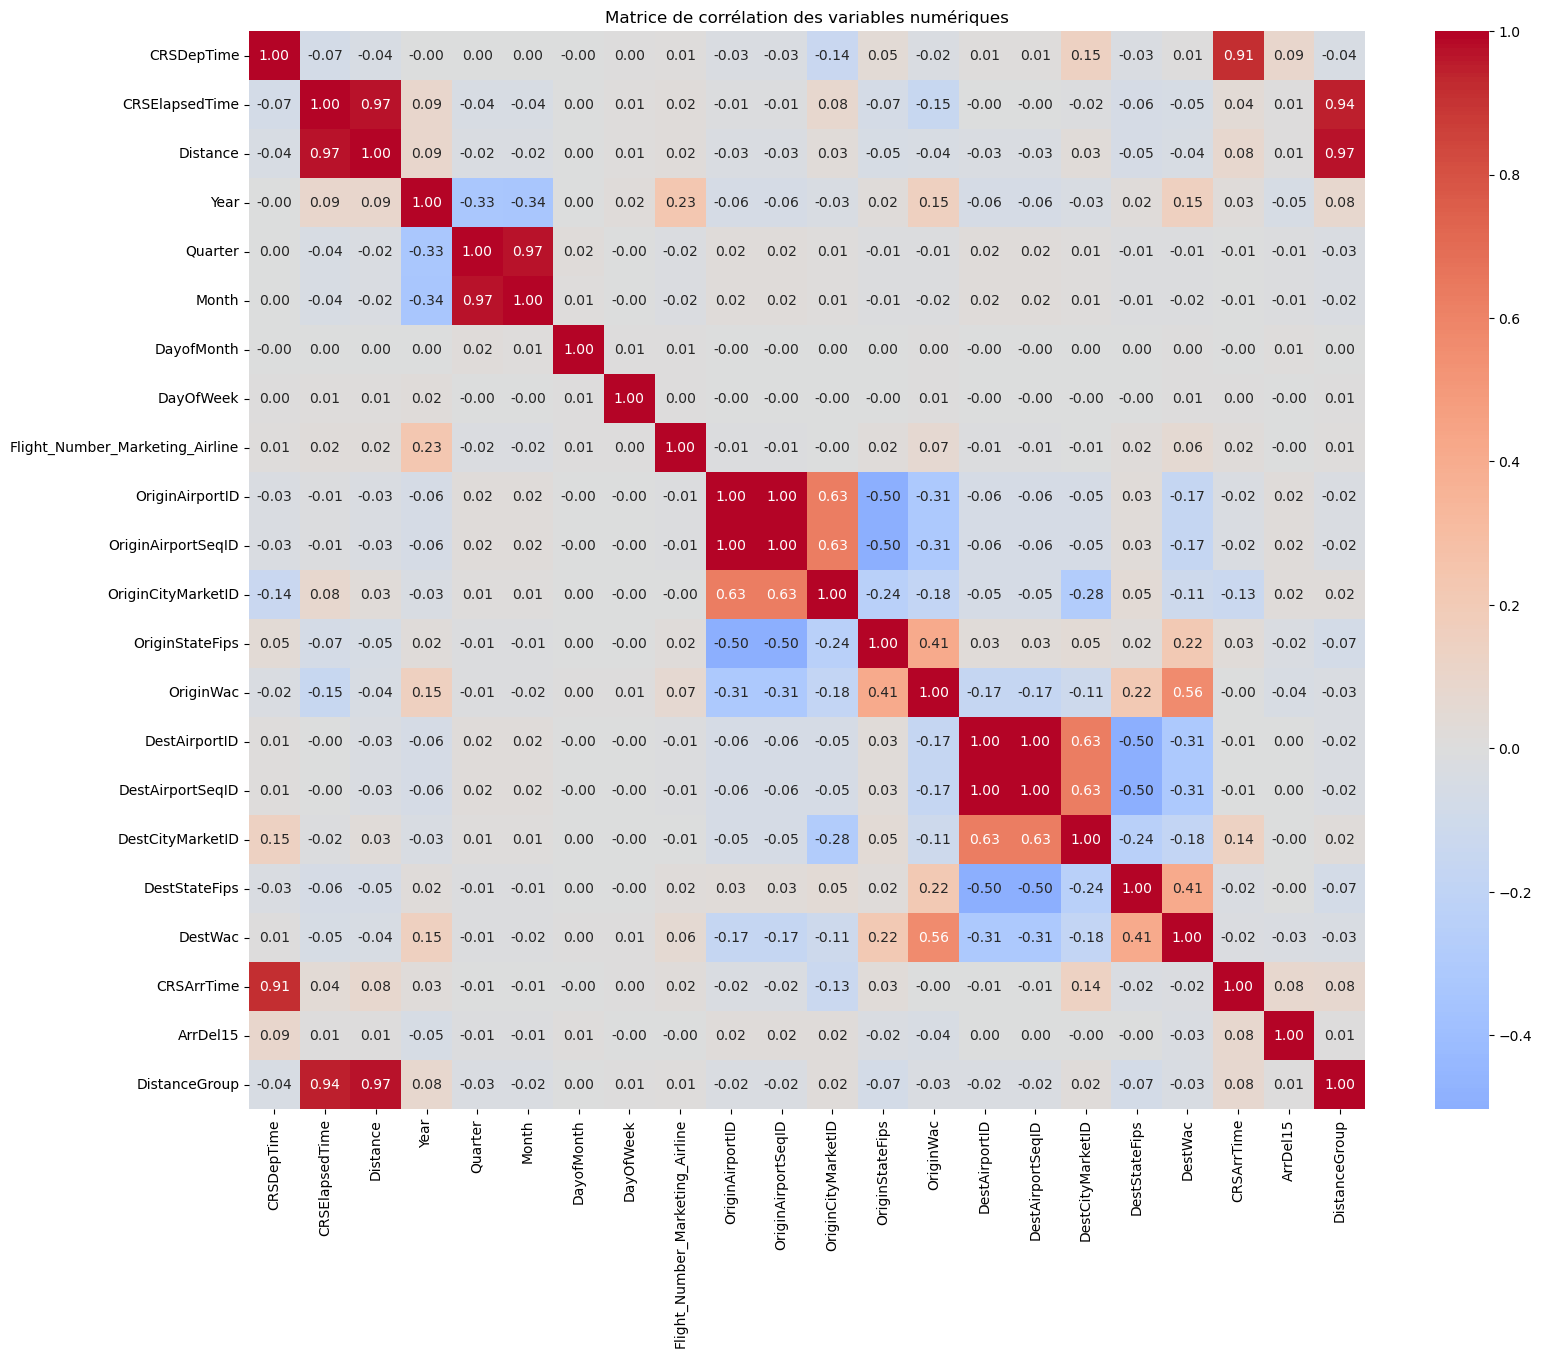

In [62]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sélectionner les variables numériques
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Calculer les corrélations
corr_matrix = df[numeric_cols].corr(method="pearson")

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matrice de corrélation des variables numériques")
plt.show()

Identification des corrélations forte

In [63]:
# Seuil de corrélation
threshold = 0.80

# Garder uniquement le triangle supérieur pour éviter les doublons
upper = corr_matrix.abs().where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Extraire les paires fortement corrélées
high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Variable 1", "Variable 2", "Corrélation"]

# Garder les corrélations >= 0.80
high_corr = high_corr[
    high_corr["Corrélation"] >= threshold
].sort_values(by="Corrélation", ascending=False)

display(high_corr)

,Variable 1,Variable 2,Corrélation
203,DestAirportID,DestAirportSeqID,1.000000
153,OriginAirportID,OriginAirportSeqID,1.000000
59,Distance,DistanceGroup,0.974447
78,Quarter,Month,0.971553
21,CRSElapsedTime,Distance,0.968324
40,CRSElapsedTime,DistanceGroup,0.944791
18,CRSDepTime,CRSArrTime,0.912285


COMPARAISON DES CORRÉLATIONS AVEC LA CIBLE

In [64]:

# Paires de variables fortement corrélées
correlated_pairs = [
    ("OriginAirportID", "OriginAirportSeqID"),
    ("DestAirportID", "DestAirportSeqID"),
    ("Distance", "DistanceGroup"),
    ("Quarter", "Month"),
    ("CRSElapsedTime", "Distance"),
    ("CRSElapsedTime", "DistanceGroup"),
    ("CRSDepTime", "CRSArrTime")
]

# Comparer la corrélation de chaque variable avec ArrDel15
results = []

for col1, col2 in correlated_pairs:

    corr1 = df[col1].corr(df["ArrDel15"])
    corr2 = df[col2].corr(df["ArrDel15"])

    results.append({
        "Variable 1": col1,
        "Corrélation cible 1": round(corr1, 4),
        "Variable 2": col2,
        "Corrélation cible 2": round(corr2, 4)
    })

# Afficher les résultats
comparison_df = pd.DataFrame(results)

display(comparison_df)

,Variable 1,Corrélation cible 1,Variable 2,Corrélation cible 2
0,OriginAirportID,0.0223,OriginAirportSeqID,0.0223
1,DestAirportID,0.0006,DestAirportSeqID,0.0006
2,Distance,0.0051,DistanceGroup,0.0061
3,Quarter,-0.0128,Month,-0.0138
4,CRSElapsedTime,0.0077,Distance,0.0051
5,CRSElapsedTime,0.0077,DistanceGroup,0.0061
6,CRSDepTime,0.0851,CRSArrTime,0.0821


Suppression des variables redondantes

In [66]:
cols_to_drop = [
    "OriginAirportSeqID",
    "DestAirportSeqID",
    "DistanceGroup",
    "Quarter"
]

# Supprimer les variables redondantes
df = df.drop(columns=cols_to_drop)

# Vérification
print("Colonnes supprimées :", cols_to_drop)
print("Dimensions restantes :", df.shape)

Colonnes supprimées : ['OriginAirportSeqID', 'DestAirportSeqID', 'DistanceGroup', 'Quarter']
Dimensions restantes : (1033979, 26)


Justification

In [ ]:
# ==========================================
# 13.6 SUPPRESSION DES VARIABLES REDONDANTES
# ==========================================

# OriginAirportSeqID :
# On conserve OriginAirportID, qui identifie l'aéroport
# sans ajouter d'information utile supplémentaire.

# DestAirportSeqID :
# On conserve DestAirportID pour la même raison.

# DistanceGroup :
# On conserve Distance, qui donne la distance exacte
# plutôt qu'une catégorie de distance.

# Quarter :
# On conserve Month, qui donne une information temporelle
# plus précise que le trimestre.

Identifier les variables numériques à examiner.

In [67]:
numeric_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("ArrDel15")

print("Variables numériques :", len(numeric_cols))
print(list(numeric_cols))

Variables numériques : 17
['CRSDepTime', 'CRSElapsedTime', 'Distance', 'Year', 'Month', 'DayofMonth', 'DayOfWeek', 'Flight_Number_Marketing_Airline', 'OriginAirportID', 'OriginCityMarketID', 'OriginStateFips', 'OriginWac', 'DestAirportID', 'DestCityMarketID', 'DestStateFips', 'DestWac', 'CRSArrTime']


Visualiser les distributions avec des Boxplots.

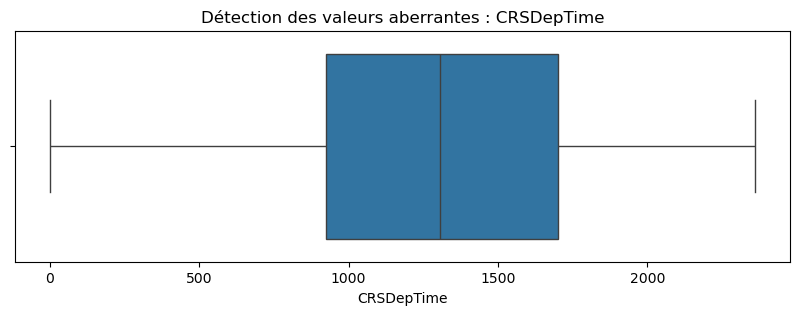

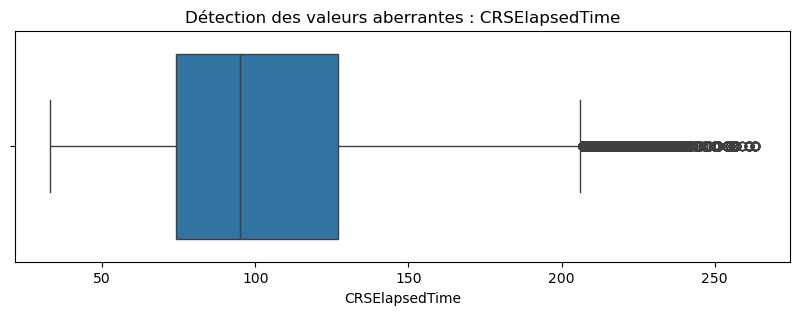

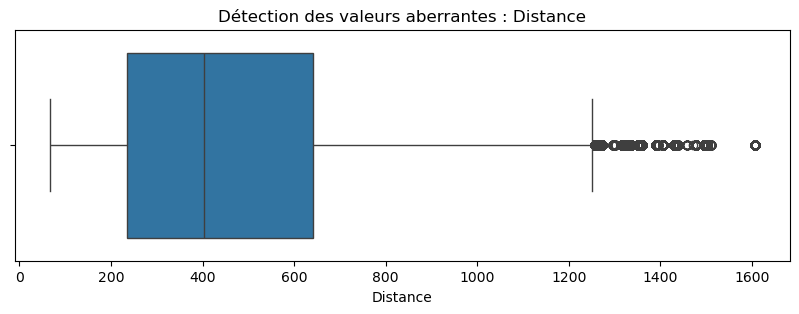

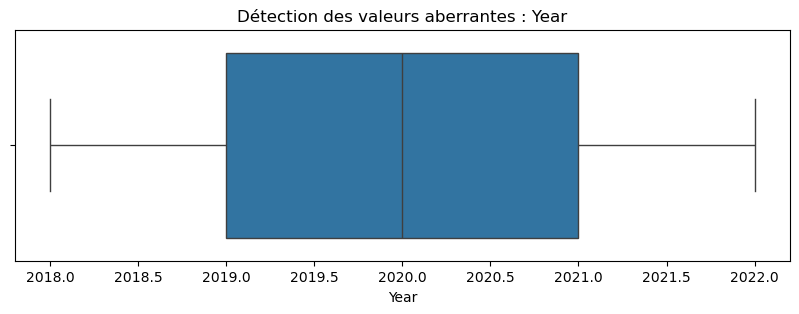

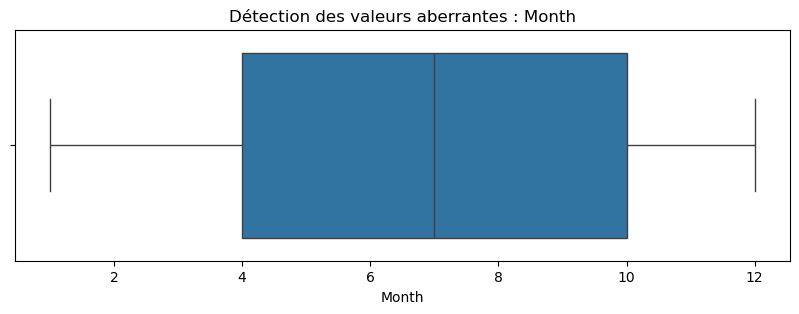

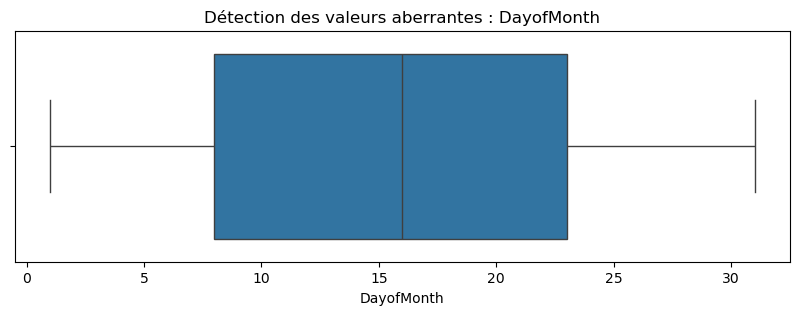

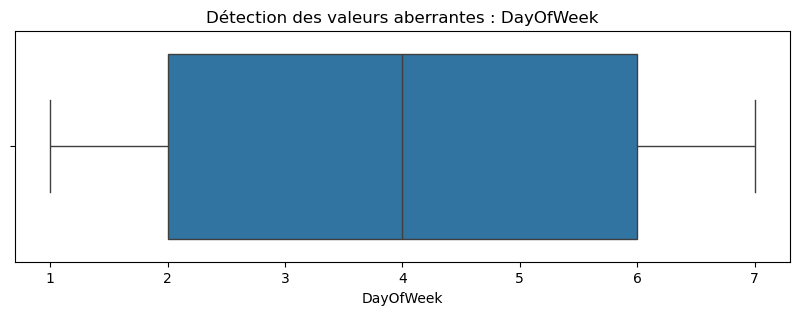

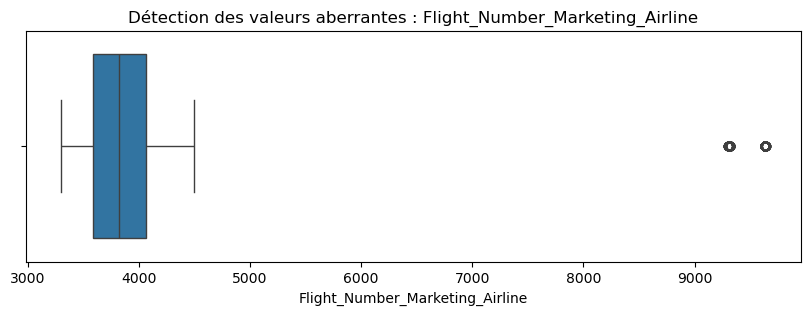

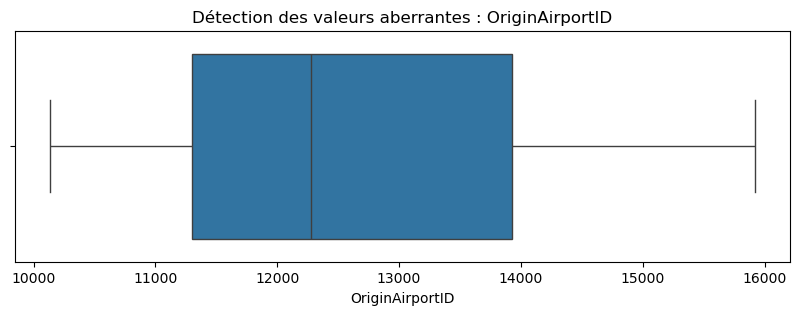

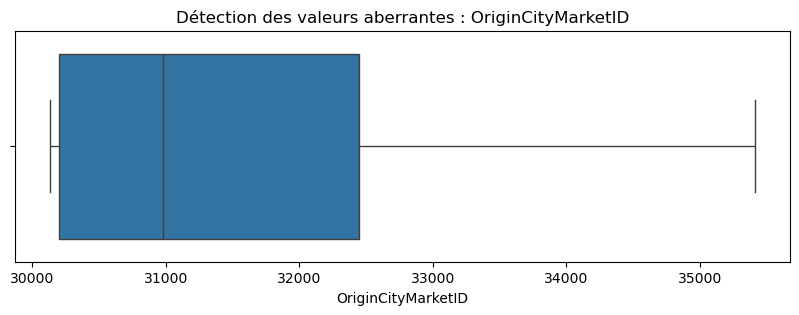

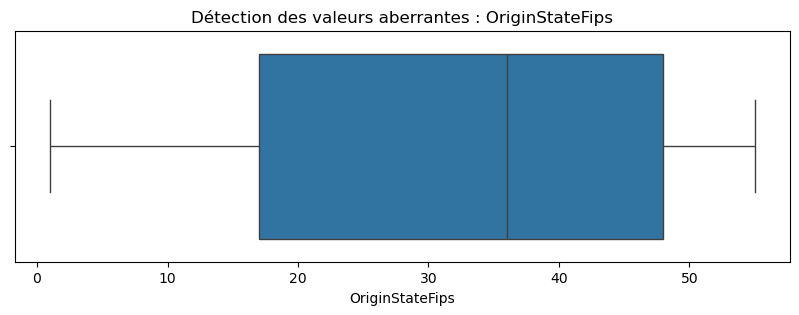

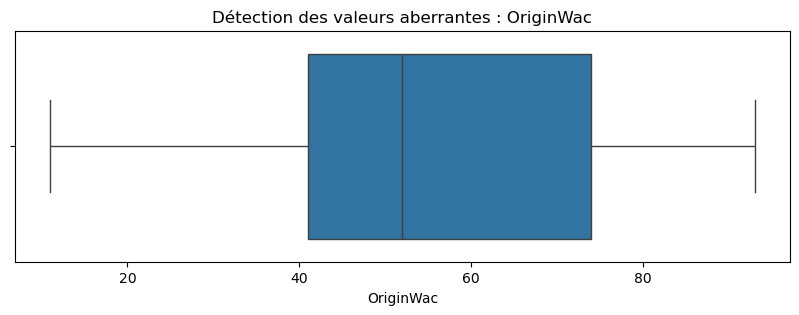

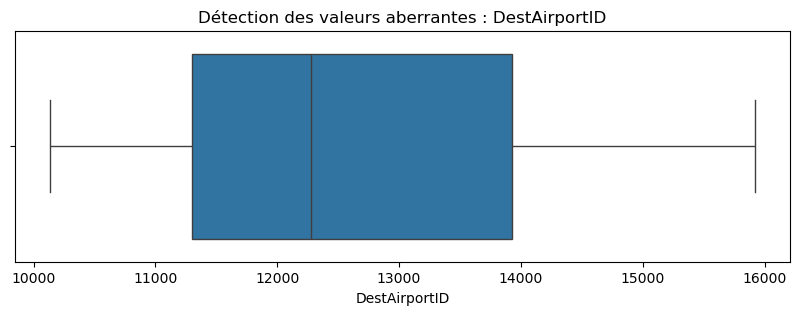

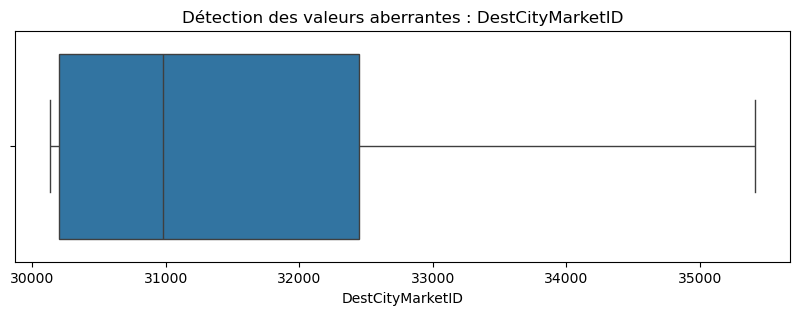

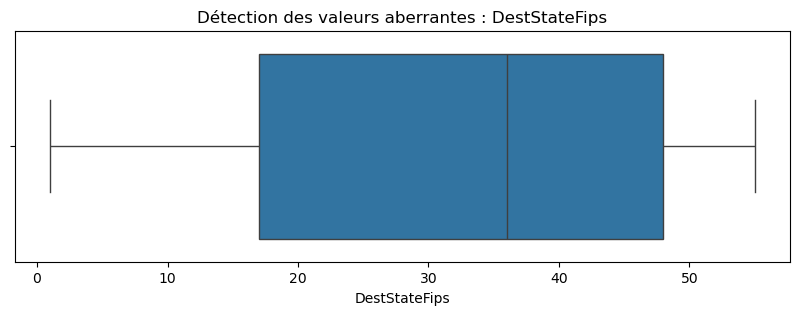

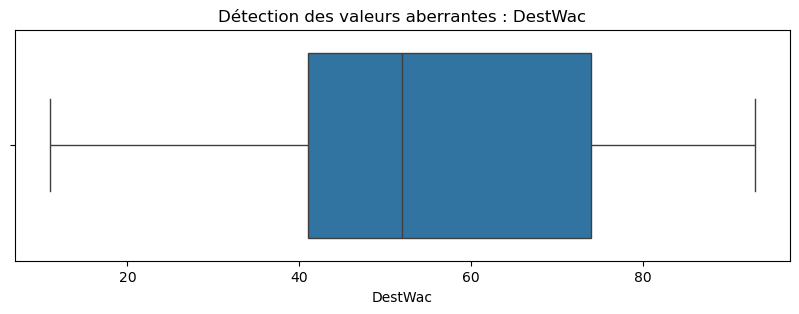

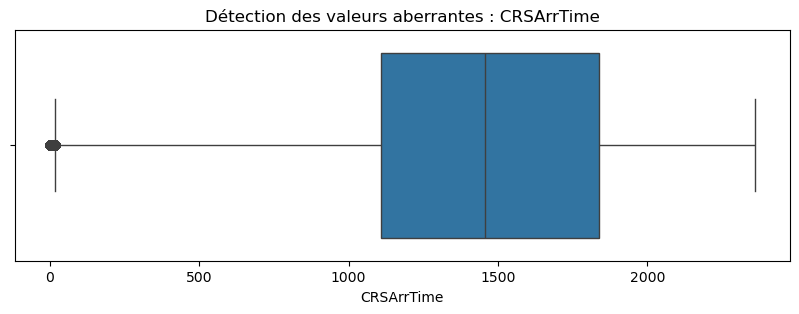

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_cols:

    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Détection des valeurs aberrantes : {col}")
    plt.xlabel(col)

    plt.show()

Vérifier les heures proches de 0

In [69]:
# Examiner les heures d'arrivée les plus petites
print("Heures d'arrivée les plus petites :")
display(df["CRSArrTime"].value_counts().sort_index().head(20))

# Examiner les heures de départ les plus petites
print("\nHeures de départ les plus petites :")
display(df["CRSDepTime"].value_counts().sort_index().head(20))

# Vérifier les heures impossibles
invalid_arr = df[
    (df["CRSArrTime"] > 2359) |
    ((df["CRSArrTime"] % 100) >= 60)
]

invalid_dep = df[
    (df["CRSDepTime"] > 2359) |
    ((df["CRSDepTime"] % 100) >= 60)
]

print("\nHeures d'arrivée invalides :", len(invalid_arr))
print("Heures de départ invalides :", len(invalid_dep))

Heures d'arrivée les plus petites :


CRSArrTime
1     281
2     200
3     284
4     399
5     192
6     297
7     200
8     222
9     358
10    127
11    212
12    193
13     85
14    152
15    270
16    208
17    102
18    147
19    150
20    106
Name: count, dtype: int64


Heures de départ les plus petites :


CRSDepTime
1      2
4      3
5     10
6      1
7      2
8      4
9      6
10     4
11     3
12     1
13     2
15     1
16     2
17     3
19     7
20     6
30     1
34     2
35     4
37     1
Name: count, dtype: int64


Heures d'arrivée invalides : 0
Heures de départ invalides : 0


Quantifier les outliers

In [70]:

# Variables quantitatives pertinentes
outlier_cols = [
    "CRSElapsedTime",
    "Distance"
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Identifier les valeurs aberrantes
    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\n--- {col} ---")
    print("Limite inférieure :", round(lower_limit, 2))
    print("Limite supérieure :", round(upper_limit, 2))
    print("Nombre d'outliers :", len(outliers))
    print("Pourcentage :", round(len(outliers) / len(df) * 100, 2), "%")


--- CRSElapsedTime ---
Limite inférieure : -5.5
Limite supérieure : 206.5
Nombre d'outliers : 17498
Pourcentage : 1.69 %

--- Distance ---
Limite inférieure : -376.5
Limite supérieure : 1251.5
Nombre d'outliers : 22238
Pourcentage : 2.15 %


Examiner la distribution des variables numériques

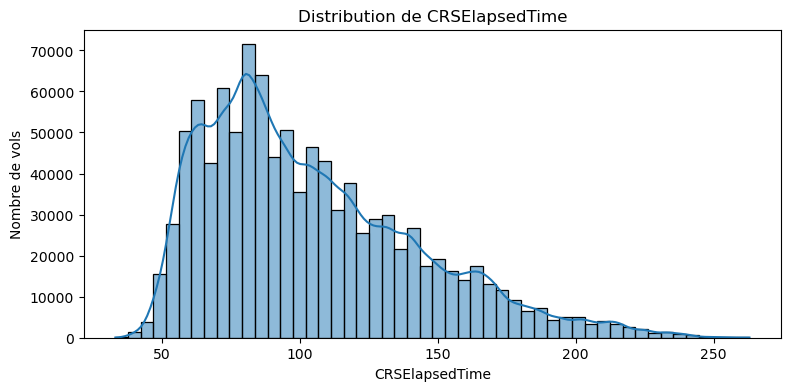

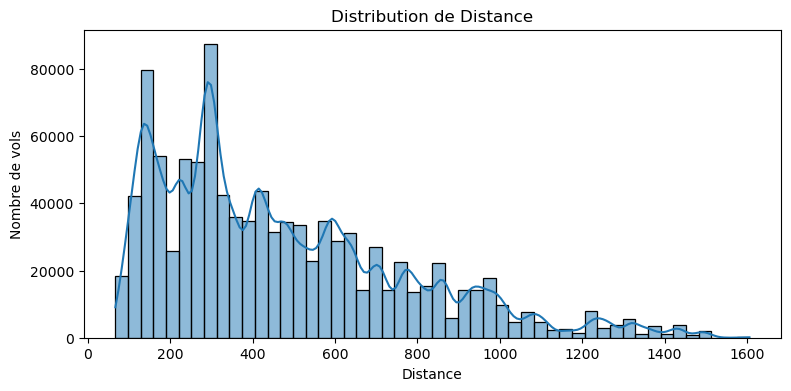

In [71]:

numeric_cols = ["CRSElapsedTime", "Distance"]

for col in numeric_cols:

    plt.figure(figsize=(9, 4))

    sns.histplot(df[col], bins=50, kde=True)

    plt.title(f"Distribution de {col}")
    plt.xlabel(col)
    plt.ylabel("Nombre de vols")

    plt.show()

Déséquilibre de la variable cible

ArrDel15
0.0    854156
1.0    179823
Name: count, dtype: int64

ArrDel15
0.0    82.61
1.0    17.39
Name: proportion, dtype: float64

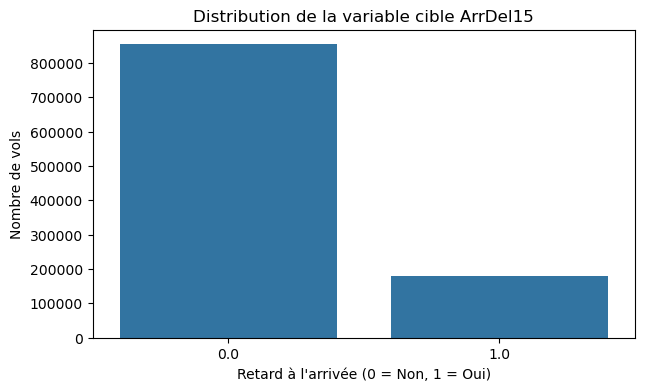

In [72]:
# Nombre de vols par classe
display(df["ArrDel15"].value_counts())

# Pourcentage de chaque classe
display(
    (df["ArrDel15"].value_counts(normalize=True) * 100).round(2)
)

# Visualisation
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="ArrDel15")

plt.title("Distribution de la variable cible ArrDel15")
plt.xlabel("Retard à l'arrivée (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de vols")

plt.show()

Examiner les variables catégorielles restantes

In [73]:
# Identifier les variables catégorielles
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

print("Nombre de variables catégorielles :", len(categorical_cols))

# Examiner chaque variable
for col in categorical_cols:

    print(f"\n--- {col} ---")

    print("Nombre de catégories :", df[col].nunique())

    # Afficher les 15 catégories les plus fréquentes
    display(df[col].value_counts().head(15))

    # Pourcentage des catégories les plus fréquentes
    display(
        (df[col].value_counts(normalize=True).head(15) * 100).round(2)
    )

Nombre de variables catégorielles : 8

--- FlightDate ---
Nombre de catégories : 1461


FlightDate
2019-08-09    1011
2019-07-26    1010
2019-07-28    1007
2019-08-05    1007
2019-08-02    1005
2019-07-12    1005
2019-07-24    1005
2019-08-11    1002
2019-07-19     999
2019-08-16     998
2019-08-29     997
2019-08-04     995
2019-07-25     993
2019-08-01     993
2019-07-09     990
Name: count, dtype: int64

FlightDate
2019-08-09    0.1
2019-07-26    0.1
2019-07-28    0.1
2019-08-05    0.1
2019-08-02    0.1
2019-07-12    0.1
2019-07-24    0.1
2019-08-11    0.1
2019-07-19    0.1
2019-08-16    0.1
2019-08-29    0.1
2019-08-04    0.1
2019-07-25    0.1
2019-08-01    0.1
2019-07-09    0.1
Name: proportion, dtype: float64


--- Origin ---
Nombre de catégories : 190


Origin
DFW    231420
ORD    187610
MIA     42385
LGA     19348
SGF     16273
XNA     15198
CVG     15048
CMH     13819
CLT     13102
LIT     12929
GSO      9320
CLE      7694
ABI      7596
JFK      7589
GRK      7526
Name: count, dtype: int64

Origin
DFW    22.38
ORD    18.14
MIA     4.10
LGA     1.87
SGF     1.57
XNA     1.47
CVG     1.46
CMH     1.34
CLT     1.27
LIT     1.25
GSO     0.90
CLE     0.74
ABI     0.73
JFK     0.73
GRK     0.73
Name: proportion, dtype: float64

... (14 outputs left out)

DepTimeBlk
1200-1259    8.39
1000-1059    8.34
0800-0859    7.74
0600-0659    7.34
1600-1659    7.14
1400-1459    6.89
1800-1859    6.88
1500-1559    6.12
0700-0759    5.72
1300-1359    5.48
1700-1759    5.26
1100-1159    5.21
2000-2059    5.08
0900-0959    4.49
1900-1959    3.84
Name: proportion, dtype: float64


--- ArrTimeBlk ---
Nombre de catégories : 19


ArrTimeBlk
1100-1159    85832
1700-1759    85174
1500-1559    79104
0900-0959    75474
1900-1959    75081
1400-1459    66789
1200-1259    64441
0700-0759    62475
1300-1359    61144
1600-1659    56266
1000-1059    55407
2100-2159    55085
1800-1859    52216
2200-2259    39973
2000-2059    37044
Name: count, dtype: int64

ArrTimeBlk
1100-1159    8.30
1700-1759    8.24
1500-1559    7.65
0900-0959    7.30
1900-1959    7.26
1400-1459    6.46
1200-1259    6.23
0700-0759    6.04
1300-1359    5.91
1600-1659    5.44
1000-1059    5.36
2100-2159    5.33
1800-1859    5.05
2200-2259    3.87
2000-2059    3.58
Name: proportion, dtype: float64

Examiner les variables temporelles

In [74]:
# Vérifier le format de FlightDate
print("Type de FlightDate :", df["FlightDate"].dtype)

# Examiner quelques dates
display(df["FlightDate"].head(10))

# Examiner les périodes disponibles
print("\nDate minimale :", df["FlightDate"].min())
print("Date maximale :", df["FlightDate"].max())

# Vérifier les variables temporelles existantes
display(df[[
    "Year",
    "Month",
    "DayofMonth",
    "DayOfWeek"
]].head())

Type de FlightDate : object


0    2018-10-26
1    2018-10-27
2    2018-10-28
3    2018-10-29
4    2018-10-30
5    2018-10-04
6    2018-10-05
7    2018-10-06
8    2018-10-07
9    2018-10-08
Name: FlightDate, dtype: object


Date minimale : 2018-08-01
Date maximale : 2022-07-31


,Year,Month,DayofMonth,DayOfWeek
0,2018,10,26,5
1,2018,10,27,6
2,2018,10,28,7
3,2018,10,29,1
4,2018,10,30,2


Convertir FlightDate en datetime

In [75]:

# Convertir FlightDate en format datetime
df["FlightDate"] = pd.to_datetime(df["FlightDate"])

# Vérifier le résultat
print("Type après conversion :", df["FlightDate"].dtype)

# Vérifier les dates
print("Date minimale :", df["FlightDate"].min())
print("Date maximale :", df["FlightDate"].max())

Type après conversion : datetime64[ns]
Date minimale : 2018-08-01 00:00:00
Date maximale : 2022-07-31 00:00:00


In [76]:
# ==========================================
# 17.3 VÉRIFICATION DES VARIABLES TEMPORELLES
# ==========================================

# Vérifier si les variables existantes correspondent à FlightDate
print("Année identique :",
      (df["Year"] == df["FlightDate"].dt.year).all())

print("Mois identique :",
      (df["Month"] == df["FlightDate"].dt.month).all())

print("Jour identique :",
      (df["DayofMonth"] == df["FlightDate"].dt.day).all())

# Vérifier le jour de la semaine
# BTS utilise 1 = lundi et 7 = dimanche
print("Jour de semaine identique :",
      (df["DayOfWeek"] == df["FlightDate"].dt.dayofweek + 1).all())

Année identique : True
Mois identique : True
Jour identique : True
Jour de semaine identique : True


Supression des variables temporelles redondantes

In [78]:
temporal_cols_to_drop = [
    "Year",
    "Month",
    "DayofMonth",
    "DayOfWeek"
]

# Supprimer les variables redondantes
df = df.drop(columns=temporal_cols_to_drop)

# Vérification
print("Colonnes supprimées :", temporal_cols_to_drop)
print("Dimensions restantes :", df.shape)

KeyError: "['Year', 'Month', 'DayofMonth', 'DayOfWeek'] not found in axis"

Extraire informations temporelles

In [79]:


# Extraire le mois
df["Month"] = df["FlightDate"].dt.month

# Extraire le jour du mois
df["DayofMonth"] = df["FlightDate"].dt.day

# Extraire le jour de la semaine (1 = lundi, 7 = dimanche)
df["DayOfWeek"] = df["FlightDate"].dt.dayofweek + 1

# Vérification
display(df[[
    "FlightDate",
    "Month",
    "DayofMonth",
    "DayOfWeek"
]].head())

,FlightDate,Month,DayofMonth,DayOfWeek
0,2018-10-26,10,26,5
1,2018-10-27,10,27,6
2,2018-10-28,10,28,7
3,2018-10-29,10,29,1
4,2018-10-30,10,30,2


Supression de tail number

In [80]:
# ==========================================
# 18. SUPPRESSION DE TAIL_NUMBER
# ==========================================

# Tail_Number :
# Identifie individuellement chaque avion.
# Peut favoriser le surapprentissage en permettant au modèle
# de mémoriser les caractéristiques associées à certains avions.
# Cette variable n'est pas indispensable à notre prédiction.

df = df.drop(columns=["Tail_Number"])

# Vérification
print("Tail_Number supprimée :", "Tail_Number" not in df.columns)
print("Dimensions restantes :", df.shape)

Tail_Number supprimée : True
Dimensions restantes : (1033979, 24)


Afficher les variables restantes

In [81]:

# Identifier les variables catégorielles
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

print("Nombre de variables catégorielles :", len(categorical_cols))
print("\nVariables :", list(categorical_cols))

# Examiner leur nombre de catégories
for col in categorical_cols:
    print(f"{col} : {df[col].nunique()} catégories")

Nombre de variables catégorielles : 6

Variables : ['Origin', 'Dest', 'OriginState', 'DestState', 'DepTimeBlk', 'ArrTimeBlk']
Origin : 190 catégories
Dest : 190 catégories
OriginState : 46 catégories
DestState : 46 catégories
DepTimeBlk : 19 catégories
ArrTimeBlk : 19 catégories


Examiner les variables numériques restantes

In [82]:
# ==========================================
# 19.2 EXAMEN DES TYPES DE VARIABLES
# ==========================================

display(
    df.dtypes.to_frame(name="Type")
)

print("\nDimensions actuelles :", df.shape)

,Type
FlightDate,datetime64[ns]
Origin,object
Dest,object
CRSDepTime,int64
CRSElapsedTime,float64
Distance,float64
Flight_Number_Marketing_Airline,int64
OriginAirportID,int64
OriginCityMarketID,int64
OriginState,object



Dimensions actuelles : (1033979, 24)


Examiner la relation des catégories avec ArrDel15

In [83]:
categorical_cols = [
    "Origin",
    "Dest",
    "OriginState",
    "DestState",
    "DepTimeBlk",
    "ArrTimeBlk"
]

for col in categorical_cols:

    print(f"\n========== {col} ==========")

    # Nombre de vols et taux de retard par catégorie
    analysis = df.groupby(col)["ArrDel15"].agg(
        Nombre_vols="count",
        Taux_retard="mean"
    )

    # Convertir en pourcentage
    analysis["Taux_retard"] = (
        analysis["Taux_retard"] * 100
    ).round(2)

    # Afficher les 15 catégories les plus fréquentes
    display(
        analysis.sort_values(
            by="Nombre_vols",
            ascending=False
        ).head(15)
    )


========== Origin ==========


,Nombre_vols,Taux_retard
Origin,,
DFW,231420,14.38
ORD,187610,18.98
MIA,42385,17.83
LGA,19348,27.54
SGF,16273,17.97
XNA,15198,16.95
CVG,15048,19.69
CMH,13819,19.63
CLT,13102,19.56



========== Dest ==========


,Nombre_vols,Taux_retard
Dest,,
DFW,230937,17.13
ORD,187147,17.49
MIA,42259,16.99
LGA,19207,27.31
SGF,16282,17.31
XNA,15214,17.31
CVG,15093,19.47
CMH,13811,19.89
CLT,13104,15.31



========== OriginState ==========


,Nombre_vols,Taux_retard
OriginState,,
TX,314815,14.97
IL,206506,18.68
FL,66016,18.16
NY,37592,23.54
AR,34745,17.32
NC,32150,18.50
OH,29344,18.40
MO,29330,17.48
KY,24774,18.85


... (2 outputs left out)


========== DepTimeBlk ==========


,Nombre_vols,Taux_retard
DepTimeBlk,,
1200-1259,86701,16.46
1000-1059,86212,15.75
0800-0859,80026,13.87
0600-0659,75848,11.03
1600-1659,73840,20.49
1400-1459,71190,18.45
1800-1859,71168,22.37
1500-1559,63280,21.17
0700-0759,59092,13.67



========== ArrTimeBlk ==========


,Nombre_vols,Taux_retard
ArrTimeBlk,,
1100-1159,85832,15.19
1700-1759,85174,21.08
1500-1559,79104,17.70
0900-0959,75474,14.84
1900-1959,75081,22.13
1400-1459,66789,17.01
1200-1259,64441,14.97
0700-0759,62475,10.62
1300-1359,61144,16.20


Vérification des identifiants numériques

In [84]:

id_cols = [
    "Flight_Number_Marketing_Airline",
    "OriginAirportID",
    "OriginCityMarketID",
    "OriginStateFips",
    "OriginWac",
    "DestAirportID",
    "DestCityMarketID",
    "DestStateFips",
    "DestWac"
]

for col in id_cols:

    print(f"\n--- {col} ---")
    print("Nombre de catégories :", df[col].nunique())

    display(df[col].value_counts().head(10))


--- Flight_Number_Marketing_Airline ---
Nombre de catégories : 1218


Flight_Number_Marketing_Airline
3777    2423
3636    2244
3624    2074
3628    2065
3795    2049
3642    2037
4194    2015
4062    1960
3922    1957
3546    1951
Name: count, dtype: int64


--- OriginAirportID ---
Nombre de catégories : 190


OriginAirportID
11298    231420
13930    187610
13303     42385
12953     19348
14783     16273
15919     15198
11193     15048
11066     13819
11057     13102
12992     12929
Name: count, dtype: int64


--- OriginCityMarketID ---
Nombre de catégories : 181


OriginCityMarketID
30194    231420
30977    187610
32467     42385
31703     28234
34783     16273
31834     15198
33105     15048
31066     13819
31057     13102
32600     12929
Name: count, dtype: int64

... (8 outputs left out)


--- DestStateFips ---
Nombre de catégories : 46


DestStateFips
48    314420
17    206059
12     65976
36     37487
5      34756
37     32225
39     29367
29     29363
21     24849
22     23244
Name: count, dtype: int64


--- DestWac ---
Nombre de catégories : 46


DestWac
74    314420
41    206059
33     65976
22     37487
71     34756
36     32225
44     29367
64     29363
52     24849
72     23244
Name: count, dtype: int64

Supprimer les identifiants redondants

In [85]:

id_cols_to_drop = [
    "OriginAirportID",
    "OriginCityMarketID",
    "OriginStateFips",
    "OriginWac",
    "DestAirportID",
    "DestCityMarketID",
    "DestStateFips",
    "DestWac"
]

# Suppression des variables
df = df.drop(columns=id_cols_to_drop)

# Vérification
print("Colonnes supprimées :", id_cols_to_drop)
print("Dimensions restantes :", df.shape)

Colonnes supprimées : ['OriginAirportID', 'OriginCityMarketID', 'OriginStateFips', 'OriginWac', 'DestAirportID', 'DestCityMarketID', 'DestStateFips', 'DestWac']
Dimensions restantes : (1033979, 16)


Justification

In [86]:

# OriginAirportID :
# Supprimée, car Origin identifie déjà l'aéroport de départ.

# OriginCityMarketID :
# Supprimée, car Origin fournit déjà l'information sur l'aéroport.

# OriginStateFips :
# Supprimée, car OriginState identifie déjà l'État de départ.

# OriginWac :
# Supprimée, car OriginState fournit déjà l'information géographique.

# DestAirportID :
# Supprimée, car Dest identifie déjà l'aéroport de destination.

# DestCityMarketID :
# Supprimée, car Dest fournit déjà l'information sur l'aéroport.

# DestStateFips :
# Supprimée, car DestState identifie déjà l'État de destination.

# DestWac :
# Supprimée, car DestState fournit déjà l'information géographique.

Sauvegarde

In [87]:
# ==========================================
# 21. SAUVEGARDE DU DATASET PRÉTRAITÉ
# ==========================================

# Sauvegarder le dataset nettoyé au format Parquet
df.to_parquet("dataset_pretraite.parquet", index=False)

print("Dataset sauvegardé avec succès !")
print("Dimensions :", df.shape)

Dataset sauvegardé avec succès !
Dimensions : (1033979, 16)


In [88]:
# ==========================================
# 21.2 VÉRIFICATION DE LA SAUVEGARDE
# ==========================================

# Recharger le dataset sauvegardé
df_check = pd.read_parquet("dataset_pretraite.parquet")

# Vérifier les dimensions
print("Dimensions originales :", df.shape)
print("Dimensions sauvegardées :", df_check.shape)

# Vérifier les types
print("\nTypes des variables :")
display(df_check.dtypes)

# Vérifier les valeurs manquantes
print("\nValeurs manquantes :", df_check.isnull().sum().sum())

Dimensions originales : (1033979, 16)
Dimensions sauvegardées : (1033979, 16)

Types des variables :


FlightDate                         datetime64[ns]
Origin                                     object
Dest                                       object
CRSDepTime                                  int64
CRSElapsedTime                            float64
Distance                                  float64
Flight_Number_Marketing_Airline             int64
OriginState                                object
DestState                                  object
DepTimeBlk                                 object
CRSArrTime                                  int64
ArrDel15                                  float64
ArrTimeBlk                                 object
Month                                       int32
DayofMonth                                  int32
DayOfWeek                                   int64
dtype: object


Valeurs manquantes : 0
